# Detección de Fraude Financiero con Machine Learning
## Notebook 04 · Evaluación
**Proyecto Final – Minería de Datos · Metodología CRISP-DM (fase 5)**

**Reglas de evaluación** (para no "elegir mirando el examen"):
1. El **umbral de decisión** de cada modelo se elige en **validación**.
2. El **mejor modelo** se elige con un criterio fijado de antemano sobre **validación**: mayor PR-AUC; si hay empate (diferencia < 0,005), el modelo más simple.
3. El conjunto de **prueba** (56 746 transacciones, 95 fraudes, nunca usado hasta ahora) solo se usa para reportar el desempeño final, con intervalos de confianza por *bootstrap*.

| Sección | Contenido |
|---|---|
| 5.1 | Modelo de costo y política de umbral |
| 5.2 | Métricas en prueba: tabla comparativa, curvas ROC y Precision-Recall, matrices de confusión |
| 5.3 | Efecto del umbral (0,5 vs. F1 vs. negocio) |
| 5.4 | Con y sin SMOTE / pesos de clase en prueba |
| 5.5 | Selección del mejor modelo y criterios de éxito |
| 5.6 | Sensibilidad al costo de revisión |
| 5.7 | Interpretabilidad con SHAP |

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(RAIZ))

import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
# shap importa tqdm, que avisa que no hay widgets de Jupyter; no afecta a los resultados
warnings.filterwarnings("ignore", message="IProgress not found")
import shap
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

from src.config import (
    FIG_DIR, MODELS_DIR, MODELOS, BALANCEOS, COLORES_MODELOS, COLORES_BALANCEO, TARGET, fijar_semillas,
)
from src.data_preprocessing import cargar_splits
from src.train_models import TIPOS, cargar_puntajes, cargar_registro
import src.evaluate as ev

fijar_semillas()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "grid.alpha": 0.35, "grid.linewidth": 0.6})
COLOR_TEXTO = "#52514e"

def guardar_figura(nombre):
    """Guarda la figura actual en reports/figures para el artículo IEEE."""
    plt.savefig(FIG_DIR / nombre, bbox_inches="tight", dpi=150)

puntajes = cargar_puntajes()
val, test = puntajes["val"], puntajes["test"]
registro = cargar_registro()
y_val, y_test = val[TARGET], test[TARGET]
VARIANTES = [c for c in val.columns if " · " in c]

print(f"Validación: {len(val):,} transacciones, {int(y_val.sum())} fraudes")
print(f"Prueba:     {len(test):,} transacciones, {int(y_test.sum())} fraudes")
print(f"Modelos finales: {MODELOS}")
print(f"Variantes de balanceo: {len(VARIANTES)}")

Validación: 56,745 transacciones, 94 fraudes
Prueba:     56,746 transacciones, 95 fraudes
Modelos finales: ['Regresión Logística', 'Random Forest', 'XGBoost', 'Stacking (RF + XGB)', 'DNN', 'Autoencoder']
Variantes de balanceo: 12


---
## 5.1 Modelo de costo y política de umbral

**Supuestos de costo** (ajustables en `src/evaluate.py`):

| Evento | Costo |
|---|---|
| Alerta (verdadero o falso positivo) | 5 € de revisión manual por alerta |
| Fraude no detectado (falso negativo) | El monto de la transacción |
| Transacción legítima no alertada | 0 € |

$$\text{Costo total} = \sum_{i \in FN} \text{Amount}_i + 5 \cdot (TP + FP)$$

**Política de umbral de negocio:** el umbral que **minimiza el costo total en validación**, con la restricción **Precision ≥ 0,70** (el equipo de revisión no puede absorber alertas de mala calidad). Como referencia también se calcula el umbral que maximiza el F1. Para el autoencoder el "umbral" se aplica sobre el error de reconstrucción.

In [2]:
umbrales = ev.calcular_umbrales(val, MODELOS + VARIANTES)

tabla_umbrales = pd.DataFrame([{
    "Modelo": m,
    "Umbral negocio": umbrales[m]["negocio"],
    "Umbral F1": umbrales[m]["f1"],
    **{f"{k} (val)": v for k, v in ev.evaluar_en_umbral(y_val, val[m], val["Amount"], umbrales[m]["negocio"]).items()
       if k in ("Precision", "Recall", "Alertas", "Costo total (€)")},
} for m in MODELOS]).set_index("Modelo")
display(tabla_umbrales.round(4))
print(f"Costo en validación sin modelo (todo el fraude se pierde): {val.loc[y_val == 1, 'Amount'].sum():,.0f} €")

,Umbral negocio,Umbral F1,Precision (val),Recall (val),Alertas (val),Costo total (€) (val)
Modelo,,,,,,
Regresión Logística,0.8482,0.9514,0.7619,0.8511,105,2548.13
Random Forest,0.3385,0.7165,0.7685,0.8830,108,2224.88
XGBoost,0.0589,0.5489,0.8218,0.8830,101,2189.88
Stacking (RF + XGB),0.0046,0.9138,0.7905,0.8830,105,2209.88
DNN,0.0683,0.5534,0.7615,0.8830,109,1918.97
Autoencoder,15.3660,7.4799,0.7045,0.3298,44,7861.92


Costo en validación sin modelo (todo el fraude se pierde): 10,067 €


---
## 5.2 Desempeño en el conjunto de prueba

In [3]:
tabla_test = ev.tabla_evaluacion(test, umbrales, MODELOS, "negocio")
costo_sin_modelo = test.loc[y_test == 1, "Amount"].sum()

# Intervalos de confianza al 95 % por bootstrap (1 000 remuestreos del conjunto de prueba)
ic = {m: ev.intervalos_bootstrap(y_test, test[m], umbrales[m]["negocio"]) for m in MODELOS}
for metrica in ("PR-AUC", "Recall", "Precision"):
    tabla_test[f"IC95 {metrica}"] = [f"[{ic[m][metrica][0]:.3f}, {ic[m][metrica][1]:.3f}]" for m in MODELOS]

columnas = ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "TP", "FP", "FN", "Costo total (€)",
            "Ahorro vs. sin modelo (%)"]
display(tabla_test[columnas].round(4))
display(tabla_test[["IC95 PR-AUC", "IC95 Recall", "IC95 Precision"]])
print(f"Costo en prueba sin modelo: {costo_sin_modelo:,.2f} €")

,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,Costo total (€),Ahorro vs. sin modelo (%)
Modelo,,,,,,,,,,
Regresión Logística,0.7872,0.7789,0.7831,0.9562,0.6952,74,20,21,4278.38,71.0261
Random Forest,0.7451,0.8000,0.7716,0.9671,0.8126,76,26,19,4296.58,70.9028
XGBoost,0.8298,0.8211,0.8254,0.9722,0.8291,78,16,17,4247.55,71.2349
Stacking (RF + XGB),0.7500,0.8211,0.7839,0.9714,0.8167,78,26,17,4301.79,70.8675
DNN,0.8111,0.7684,0.7892,0.9443,0.7799,73,17,22,4501.56,69.5147
Autoencoder,0.7353,0.2632,0.3876,0.9464,0.4934,25,9,70,13393.18,9.2991


,IC95 PR-AUC,IC95 Recall,IC95 Precision
Modelo,,,
Regresión Logística,"[0.593, 0.798]","[0.694, 0.859]","[0.703, 0.866]"
Random Forest,"[0.732, 0.888]","[0.722, 0.878]","[0.660, 0.825]"
XGBoost,"[0.755, 0.901]","[0.742, 0.897]","[0.750, 0.899]"
Stacking (RF + XGB),"[0.736, 0.893]","[0.741, 0.896]","[0.669, 0.831]"
DNN,"[0.700, 0.857]","[0.680, 0.848]","[0.730, 0.890]"
Autoencoder,"[0.391, 0.602]","[0.179, 0.342]","[0.588, 0.875]"


Costo en prueba sin modelo: 14,766.31 €


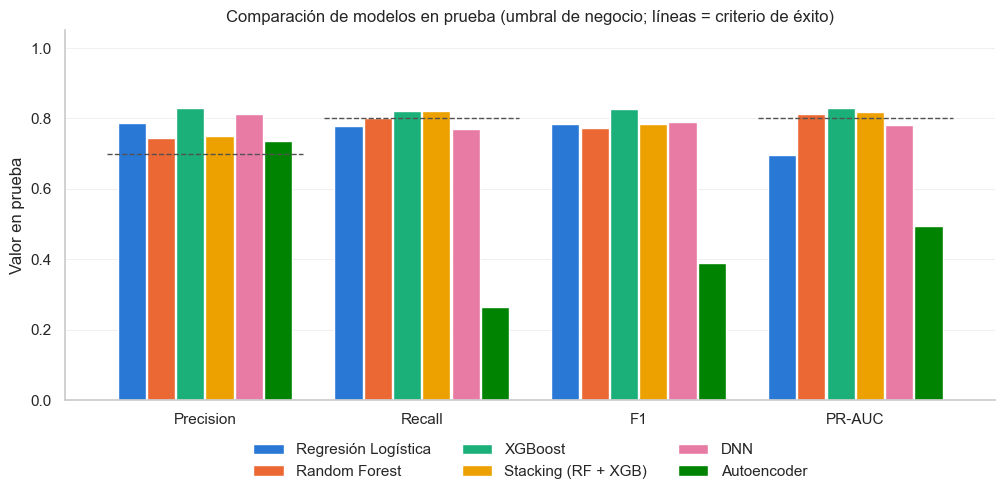

In [4]:
metricas = ["Precision", "Recall", "F1", "PR-AUC"]
fig, ax = plt.subplots(figsize=(12, 4.8))
ancho = 0.13
x = np.arange(len(metricas))
for i, m in enumerate(MODELOS):
    ax.bar(x + (i - (len(MODELOS) - 1) / 2) * (ancho + 0.005), tabla_test.loc[m, metricas],
           width=ancho, color=COLORES_MODELOS[m], label=m)
for criterio, valor in ev.CRITERIOS_EXITO.items():
    j = metricas.index(criterio)
    ax.hlines(valor, j - 0.45, j + 0.45, color=COLOR_TEXTO, linestyle="--", linewidth=1)
ax.set_xticks(x, metricas)
ax.set_ylim(0, 1.05)
ax.set(ylabel="Valor en prueba", title="Comparación de modelos en prueba (umbral de negocio; líneas = criterio de éxito)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.grid(axis="x", visible=False)
guardar_figura("14_comparacion_metricas.png")
plt.show()

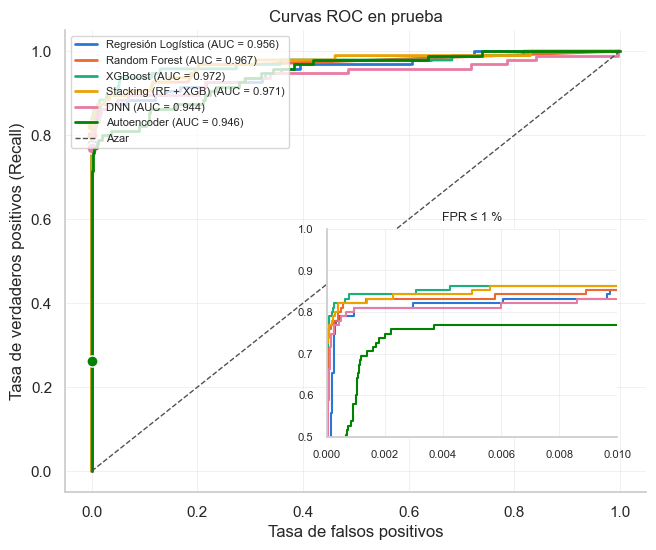

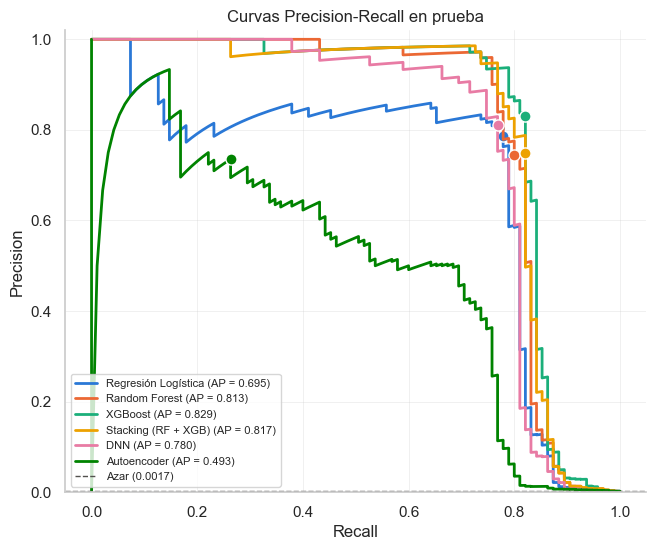

In [5]:
# Curvas ROC y Precision-Recall en prueba. El punto marca el umbral de negocio de cada modelo.
for tipo, archivo in (("roc", "15_curvas_roc.png"), ("pr", "16_curvas_pr.png")):
    fig, ax = plt.subplots(figsize=(7.5, 6))
    for m in MODELOS:
        s = test[m]
        fila = tabla_test.loc[m]
        if tipo == "roc":
            fpr, tpr, _ = roc_curve(y_test, s)
            ax.plot(fpr, tpr, color=COLORES_MODELOS[m], linewidth=2, label=f"{m} (AUC = {fila['ROC-AUC']:.3f})")
            ax.plot(fila["FP"] / (fila["FP"] + fila["TN"]), fila["Recall"], "o", color=COLORES_MODELOS[m],
                    markersize=8, markeredgecolor="white")
        else:
            p, r, _ = precision_recall_curve(y_test, s)
            ax.plot(r, p, color=COLORES_MODELOS[m], linewidth=2, label=f"{m} (AP = {fila['PR-AUC']:.3f})")
            ax.plot(fila["Recall"], fila["Precision"], "o", color=COLORES_MODELOS[m],
                    markersize=8, markeredgecolor="white")
    if tipo == "roc":
        ax.plot([0, 1], [0, 1], color=COLOR_TEXTO, linestyle="--", linewidth=1, label="Azar")
        ax.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (Recall)",
               title="Curvas ROC en prueba")
        # Recuadro ampliado: con tan pocos fraudes, lo relevante está a la izquierda
        sub = ax.inset_axes([0.45, 0.12, 0.5, 0.45])
        for m in MODELOS:
            fpr, tpr, _ = roc_curve(y_test, test[m])
            sub.plot(fpr, tpr, color=COLORES_MODELOS[m], linewidth=1.5)
        sub.set_xlim(0, 0.01); sub.set_ylim(0.5, 1.0)
        sub.set_title("FPR ≤ 1 %", fontsize=9); sub.tick_params(labelsize=8)
        ax.legend(loc="upper left", fontsize=8, bbox_to_anchor=(0.0, 1.0))
    else:
        ax.axhline(y_test.mean(), color=COLOR_TEXTO, linestyle="--", linewidth=1,
                   label=f"Azar ({y_test.mean():.4f})")
        ax.set(xlabel="Recall", ylabel="Precision", title="Curvas Precision-Recall en prueba",
               ylim=(0, 1.02))
        ax.legend(loc="lower left", fontsize=8)
    guardar_figura(archivo)
    plt.show()

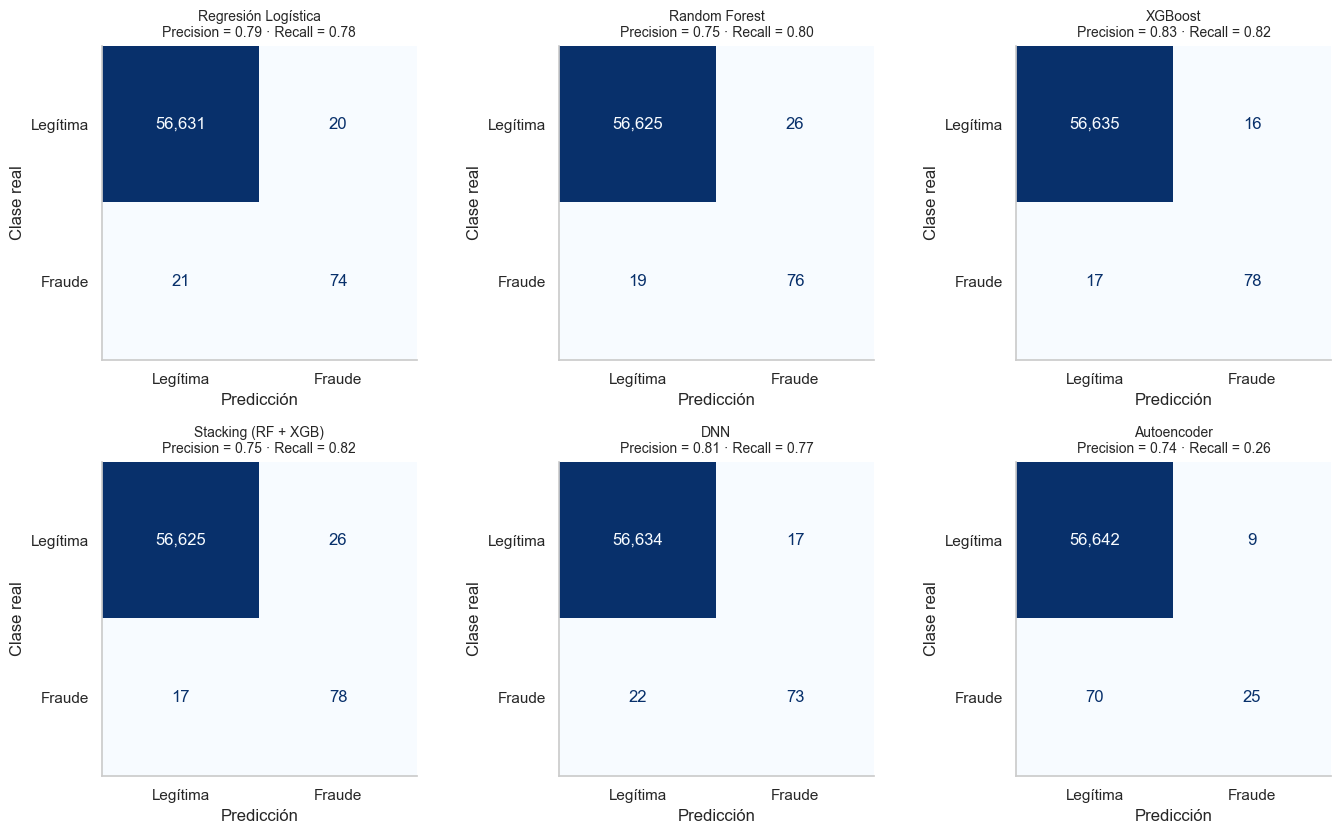

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, m in zip(axes.ravel(), MODELOS):
    pred = (test[m] >= umbrales[m]["negocio"]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Legítima", "Fraude"],
                                            cmap="Blues", colorbar=False, ax=ax, values_format=",d")
    fila = tabla_test.loc[m]
    ax.set_title(f"{m}\nPrecision = {fila['Precision']:.2f} · Recall = {fila['Recall']:.2f}", fontsize=10)
    ax.set(xlabel="Predicción", ylabel="Clase real")
    ax.grid(False)
plt.tight_layout()
guardar_figura("17_matrices_confusion.png")
plt.show()

---
## 5.3 Efecto del umbral de decisión
Se compara, para cada modelo, el umbral por defecto (0,5), el que maximiza el F1 y el de negocio. Los tres se eligen sin mirar la prueba.

In [7]:
filas = []
for m in MODELOS:
    opciones = {"0,5": 0.5, "F1 (val)": umbrales[m]["f1"], "Negocio (val)": umbrales[m]["negocio"]}
    if m == "Autoencoder":
        opciones.pop("0,5")   # el error de reconstrucción no es una probabilidad
    for nombre, t in opciones.items():
        r = ev.evaluar_en_umbral(y_test, test[m], test["Amount"], t)
        filas.append({"Modelo": m, "Umbral": nombre, "Valor": t, "Precision": r["Precision"],
                      "Recall": r["Recall"], "F1": r["F1"], "Alertas": r["Alertas"],
                      "Costo total (€)": r["Costo total (€)"]})
efecto_umbral = pd.DataFrame(filas).set_index(["Modelo", "Umbral"])
display(efecto_umbral.round(4))

Valor  Precision  Recall      F1  \
Modelo              Umbral                                              
Regresión Logística 0,5             0.5000     0.6198  0.7895  0.6944   
                    F1 (val)        0.9514     0.8256  0.7474  0.7845   
                    Negocio (val)   0.8482     0.7872  0.7789  0.7831   
Random Forest       0,5             0.5000     0.9012  0.7684  0.8295   
                    F1 (val)        0.7165     0.9710  0.7053  0.8171   
                    Negocio (val)   0.3385     0.7451  0.8000  0.7716   
XGBoost             0,5             0.5000     0.9722  0.7368  0.8383   
                    F1 (val)        0.5489     0.9718  0.7263  0.8313   
                    Negocio (val)   0.0589     0.8298  0.8211  0.8254   
Stacking (RF + XGB) 0,5             0.5000     0.9718  0.7263  0.8313   
                    F1 (val)        0.9138     0.9839  0.6421  0.7771   
                    Negocio (val)   0.0046     0.7500  0.8211  0.7839   
DNN                 0,5             0.5000     0.8765  0.7474  0.8068   
                    F1 (val)        0.5534     0.8831  0.7158  0.7907   
                    Negocio (val)   0.0683     0.8111  0.7684  0.7892   
Autoencoder         F1 (val)        7.4799     0.6308  0.4316  0.5125   
                    Negocio (val)  15.3660     0.7353  0.2632  0.3876   

                                   Alertas  Costo total (€)  
Modelo              Umbral                                   
Regresión Logística 0,5                121          4394.34  
                    F1 (val)            86          5196.46  
                    Negocio (val)       94          4278.38  
Random Forest       0,5                 81          4216.60  
                    F1 (val)            69          6207.65  
                    Negocio (val)      102          4296.58  
XGBoost             0,5                 72          4184.59  
                    F1 (val)            71          4419.52  
                    Negocio (val)       94          4247.55  
Stacking (RF + XGB) 0,5                 71          4419.52  
                    F1 (val)            62          7788.63  
                    Negocio (val)      104          4301.79  
DNN                 0,5                 81          4459.46  
                    F1 (val)            77          4739.43  
                    Negocio (val)       90          4501.56  
Autoencoder         F1 (val)            65         10832.40  
                    Negocio (val)       34         13393.18

---
## 5.4 Con y sin SMOTE / pesos de clase (prueba)
Variantes del paso 1 de la Fase 4 (hiperparámetros por defecto), cada una con su propio umbral de negocio elegido en validación.

PR-AUC  ROC-AUC  Precision  Recall  \
Modelo              Balanceo                                             
Regresión Logística Sin balanceo    0.6975   0.9484     0.7708  0.7789   
                    Pesos de clase  0.6805   0.9627     0.8182  0.7579   
                    SMOTE           0.6956   0.9577     0.8202  0.7684   
Random Forest       Sin balanceo    0.7896   0.9383     0.8488  0.7684   
                    Pesos de clase  0.8019   0.9342     0.8352  0.8000   
                    SMOTE           0.8173   0.9407     0.7027  0.8211   
XGBoost             Sin balanceo    0.8326   0.9667     0.8478  0.8211   
                    Pesos de clase  0.8191   0.9723     0.9730  0.7579   
                    SMOTE           0.8196   0.9735     0.8391  0.7684   
DNN                 Sin balanceo    0.7996   0.9570     0.8875  0.7474   
                    Pesos de clase  0.6693   0.9622     0.8372  0.7579   
                    SMOTE           0.7186   0.9475     0.8571  0.7579   

                                        F1  Costo total (€)  
Modelo              Balanceo                                 
Regresión Logística Sin balanceo    0.7749          4520.31  
                    Pesos de clase  0.7869          4233.24  
                    SMOTE           0.7935          4254.38  
Random Forest       Sin balanceo    0.8066          4222.56  
                    Pesos de clase  0.8172          4241.58  
                    SMOTE           0.7573          4336.79  
XGBoost             Sin balanceo    0.8342          4237.55  
                    Pesos de clase  0.8521          4403.17  
                    SMOTE           0.8022          4464.38  
DNN                 Sin balanceo    0.8114          4433.17  
                    Pesos de clase  0.7956          4483.78  
                    SMOTE           0.8045          4485.27

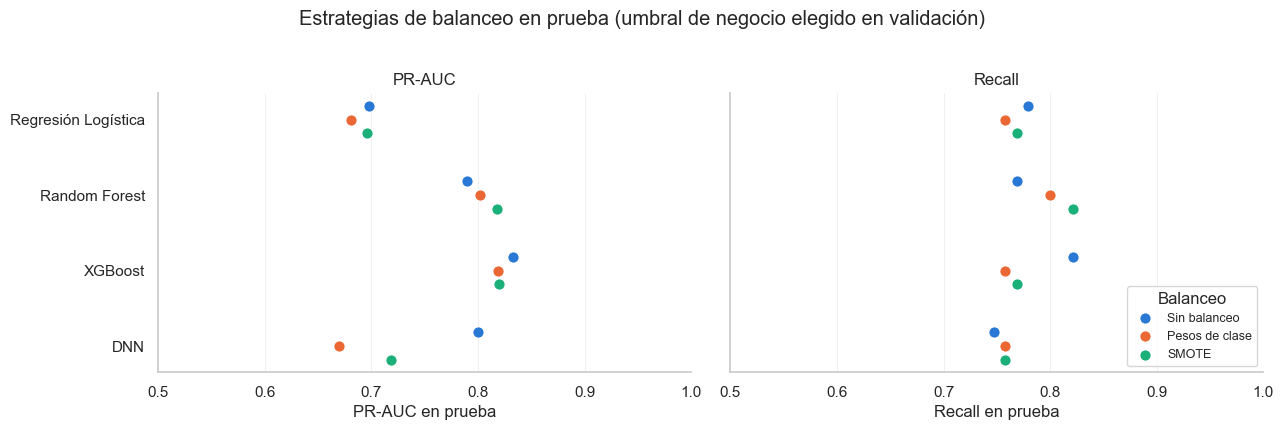

In [8]:
tabla_var = ev.tabla_evaluacion(test, umbrales, VARIANTES, "negocio")
tabla_var.index = pd.MultiIndex.from_tuples([tuple(i.split(" · ")) for i in tabla_var.index],
                                            names=["Modelo", "Balanceo"])
display(tabla_var[["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "Costo total (€)"]].round(4))

modelos_var = ["Regresión Logística", "Random Forest", "XGBoost", "DNN"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, metrica in zip(axes, ["PR-AUC", "Recall"]):
    for j, b in enumerate(BALANCEOS):
        valores = [tabla_var.loc[(m, b), metrica] for m in modelos_var]
        ax.scatter(valores, np.arange(len(modelos_var)) + (j - 1) * 0.18, s=70, color=COLORES_BALANCEO[b],
                   edgecolor="white", linewidth=1, label=b, zorder=3)
    ax.set_yticks(range(len(modelos_var)), modelos_var)
    ax.set(xlabel=f"{metrica} en prueba", title=metrica, xlim=(0.5, 1.0))
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
axes[1].legend(title="Balanceo", loc="lower right", fontsize=9)
fig.suptitle("Estrategias de balanceo en prueba (umbral de negocio elegido en validación)", y=1.02)
plt.tight_layout()
guardar_figura("18_balanceo_prueba.png")
plt.show()

---
## 5.5 Selección del mejor modelo
Criterio fijado de antemano sobre **validación**: mayor PR-AUC; si varios están a menos de 0,005 del mejor, se elige el más simple (orden: Regresión Logística < XGBoost < Random Forest < DNN < Autoencoder < Stacking).

In [9]:
MEJOR_MODELO, tabla_seleccion = ev.seleccionar_mejor_modelo(val, MODELOS)
display(tabla_seleccion.round(4))
print(f"Mejor modelo: {MEJOR_MODELO} | umbral de negocio = {umbrales[MEJOR_MODELO]['negocio']:.4f}\n")

fila = tabla_test.loc[MEJOR_MODELO]
print("Desempeño en prueba:")
for k in ("Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"):
    extra = f"  IC95 [{ic[MEJOR_MODELO][k][0]:.3f}, {ic[MEJOR_MODELO][k][1]:.3f}]" if k in ic[MEJOR_MODELO] else ""
    print(f"  {k:<10} {fila[k]:.4f}{extra}")
print(f"  Fraudes detectados: {fila['TP']} de {fila['TP'] + fila['FN']} | falsas alarmas: {fila['FP']} "
      f"de {fila['FP'] + fila['TN']:,} legítimas ({fila['FP'] / (fila['FP'] + fila['TN']):.3%})")
print(f"  Costo: {fila['Costo total (€)']:,.0f} € frente a {costo_sin_modelo:,.0f} € sin modelo "
      f"(ahorro {fila['Ahorro vs. sin modelo (%)']:.1f} %)\n")

print("Criterios de éxito (Fase 1):")
for criterio, cumple in ev.verificar_criterios(fila, fila["Ahorro vs. sin modelo (%)"]).items():
    print(f"  {'✔' if cumple else '✘'} {criterio}")

,PR-AUC (val),Complejidad,Empate con el mejor
XGBoost,0.8892,2,True
Stacking (RF + XGB),0.8892,6,True
Random Forest,0.8796,3,False
DNN,0.8734,4,False
Regresión Logística,0.8016,1,False
Autoencoder,0.5833,5,False


Mejor modelo: XGBoost | umbral de negocio = 0.0589

Desempeño en prueba:
  Precision  0.8298  IC95 [0.750, 0.899]
  Recall     0.8211  IC95 [0.742, 0.897]
  F1         0.8254  IC95 [0.766, 0.881]
  PR-AUC     0.8291  IC95 [0.755, 0.901]
  ROC-AUC    0.9722  IC95 [0.944, 0.992]
  Fraudes detectados: 78 de 95 | falsas alarmas: 16 de 56,651 legítimas (0.028%)
  Costo: 4,248 € frente a 14,766 € sin modelo (ahorro 71.2 %)

Criterios de éxito (Fase 1):
  ✔ Recall ≥ 0.80
  ✔ Precision ≥ 0.70
  ✔ PR-AUC ≥ 0.80
  ✔ Costo menor que sin modelo


---
## 5.6 Sensibilidad al costo de revisión
El costo de revisión por alerta (5 €) es un supuesto. Se recalcula el umbral de negocio del mejor modelo, en validación, para otros costos y se mide el resultado en prueba.

,Umbral,Precision,Recall,Alertas,Costo total (€),Ahorro (%)
Costo revisión (€),,,,,,
1,0.0589,0.8298,0.8211,94,3871.55,73.7812
2,0.0589,0.8298,0.8211,94,3965.55,73.1446
5,0.0589,0.8298,0.8211,94,4247.55,71.2349
10,0.0589,0.8298,0.8211,94,4717.55,68.0519
20,0.5489,0.9718,0.7263,71,5484.52,62.8579
50,0.5489,0.9718,0.7263,71,7614.52,48.4332


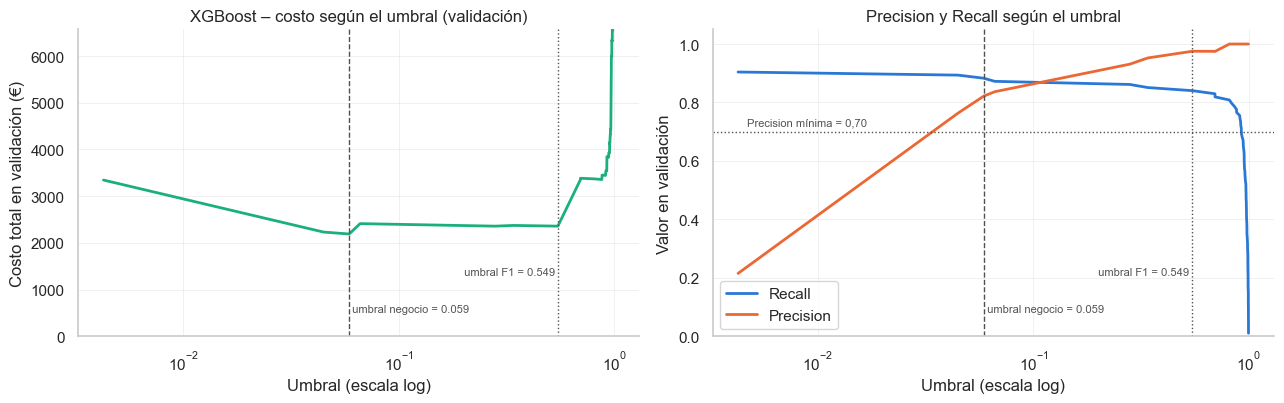

In [10]:
filas = []
for c in (1, 2, 5, 10, 20, 50):
    t = ev.umbral_negocio(y_val, val[MEJOR_MODELO], val["Amount"], costo_revision=c)
    r = ev.evaluar_en_umbral(y_test, test[MEJOR_MODELO], test["Amount"], t, costo_revision=c)
    filas.append({"Costo revisión (€)": c, "Umbral": t, "Precision": r["Precision"], "Recall": r["Recall"],
                  "Alertas": r["Alertas"], "Costo total (€)": r["Costo total (€)"],
                  "Ahorro (%)": 100 * (1 - r["Costo total (€)"] / costo_sin_modelo)})
sensibilidad = pd.DataFrame(filas).set_index("Costo revisión (€)")
display(sensibilidad.round(4))

curva = ev.curva_costo(y_val, val[MEJOR_MODELO], val["Amount"])
curva = curva[curva["Umbral"] >= 1e-3]   # por debajo, el costo se dispara y oculta la zona útil
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(curva["Umbral"], curva["Costo total (€)"], color=COLORES_MODELOS[MEJOR_MODELO], linewidth=2)
axes[0].set_ylim(0, curva["Costo total (€)"].min() * 3)
axes[0].set(ylabel="Costo total en validación (€)", title=f"{MEJOR_MODELO} – costo según el umbral (validación)")
axes[1].plot(curva["Umbral"], curva["Recall"], color=COLORES_MODELOS["Regresión Logística"], linewidth=2, label="Recall")
axes[1].plot(curva["Umbral"], curva["Precision"], color=COLORES_MODELOS["Random Forest"], linewidth=2, label="Precision")
axes[1].axhline(ev.PRECISION_MINIMA, color=COLOR_TEXTO, linestyle=":", linewidth=1)
axes[1].text(curva["Umbral"].min() * 1.1, ev.PRECISION_MINIMA + 0.02, "Precision mínima = 0,70", fontsize=8, color=COLOR_TEXTO)
axes[1].set(ylabel="Valor en validación", title="Precision y Recall según el umbral", ylim=(0, 1.05))
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Umbral (escala log)")
    for (nombre, t, estilo), altura in zip((("negocio", umbrales[MEJOR_MODELO]["negocio"], "--"),
                                            ("F1", umbrales[MEJOR_MODELO]["f1"], ":")), (0.08, 0.20)):
        ax.axvline(t, color=COLOR_TEXTO, linestyle=estilo, linewidth=1)
        ax.text(t, ax.get_ylim()[0] + altura * (ax.get_ylim()[1] - ax.get_ylim()[0]), f" umbral {nombre} = {t:.3f} ",
                fontsize=8, color=COLOR_TEXTO, ha="right" if nombre == "F1" else "left")
axes[1].legend(loc="lower left")
plt.tight_layout()
guardar_figura("19_costo_umbral.png")
plt.show()

---
## 5.7 Interpretabilidad con SHAP
**SHAP** (*SHapley Additive exPlanations*) reparte la predicción de cada transacción entre sus variables, según la teoría de juegos: cada valor SHAP es cuánto empuja esa variable la predicción (en log-odds) hacia fraude (positivo) o hacia legítima (negativo), respecto del promedio. A diferencia de la importancia por frecuencia de uso en los árboles, SHAP mide el aporte real y su dirección.

Se calcula sobre el XGBoost con una muestra del conjunto de prueba que incluye **todos los fraudes** (95) y 2 905 legítimas, para que los fraudes sean visibles en el gráfico.

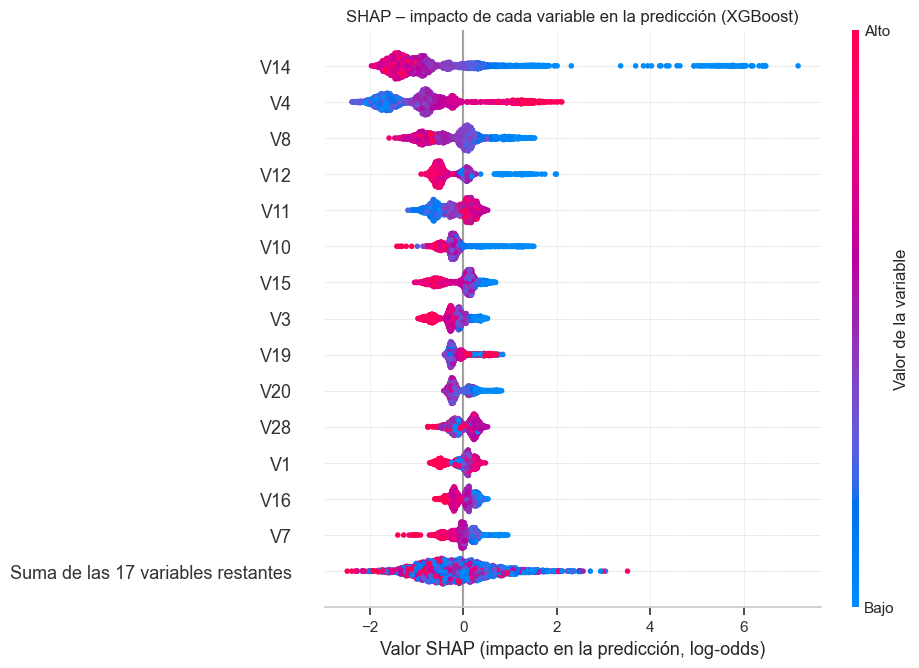

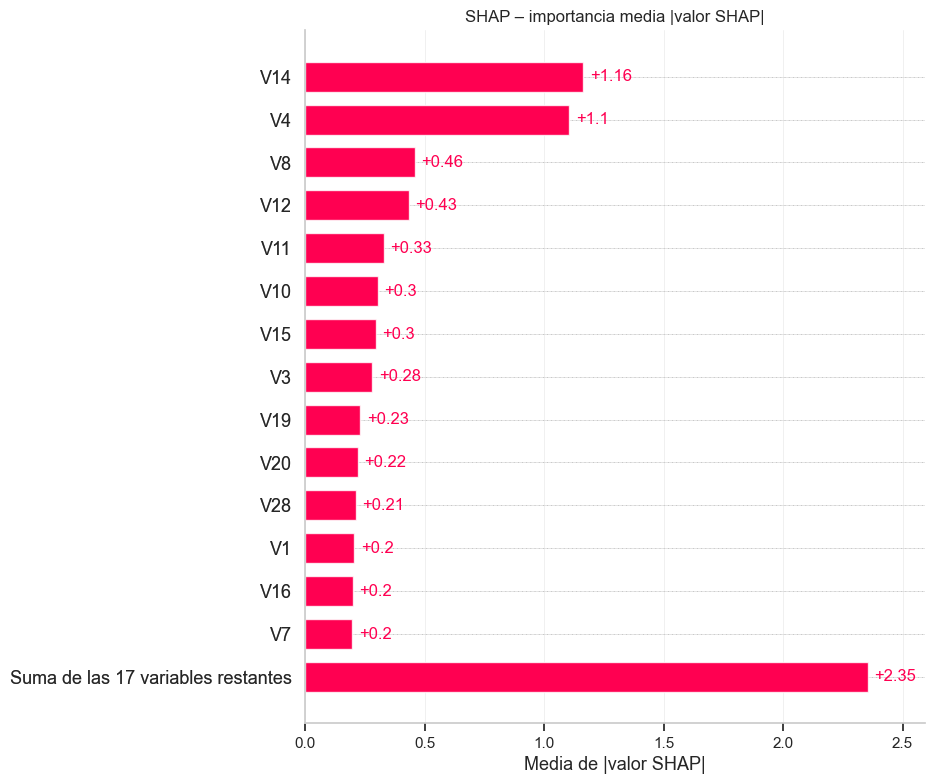

Top 10 variables por |SHAP| medio: {'V14': 1.1640000343322754, 'V4': 1.1050000190734863, 'V8': 0.4580000042915344, 'V12': 0.43299999833106995, 'V11': 0.33000001311302185, 'V10': 0.30399999022483826, 'V15': 0.29600000381469727, 'V3': 0.2809999883174896, 'V19': 0.23000000417232513, 'V20': 0.2199999988079071}


In [11]:
splits = cargar_splits()
datos_test = splits["test"]
muestra = pd.concat([datos_test[datos_test[TARGET] == 1],
                     datos_test[datos_test[TARGET] == 0].sample(2905, random_state=0)])
modelo_xgb = joblib.load(MODELS_DIR / registro["XGBoost"]["archivo"])
valores_shap = ev.explicar_shap(modelo_xgb, muestra)

def traducir_shap(xlabel):
    """SHAP rotula sus gráficos en inglés; se traducen ejes, leyenda de color y la fila agregada."""
    fig = plt.gcf()
    ax = fig.axes[0]
    ax.set_xlabel(xlabel)
    etiquetas = [t.get_text().replace("Sum of", "Suma de las").replace("other features", "variables restantes")
                 for t in ax.get_yticklabels()]
    ax.set_yticks(ax.get_yticks(), etiquetas)
    if len(fig.axes) > 1:                      # barra de color del beeswarm
        barra = fig.axes[-1]
        barra.set_ylabel("Valor de la variable")
        barra.set_yticks(barra.get_yticks(), ["Bajo", "Alto"][:len(barra.get_yticks())])

shap.plots.beeswarm(valores_shap, max_display=15, show=False)
traducir_shap("Valor SHAP (impacto en la predicción, log-odds)")
plt.title("SHAP – impacto de cada variable en la predicción (XGBoost)")
guardar_figura("20_shap_resumen.png")
plt.show()

shap.plots.bar(valores_shap, max_display=15, show=False)
traducir_shap("Media de |valor SHAP|")
plt.title("SHAP – importancia media |valor SHAP|")
guardar_figura("21_shap_importancia.png")
plt.show()

importancia = (pd.Series(np.abs(valores_shap.values).mean(axis=0), index=valores_shap.feature_names)
               .sort_values(ascending=False))
print("Top 10 variables por |SHAP| medio:", importancia.head(10).round(3).to_dict())

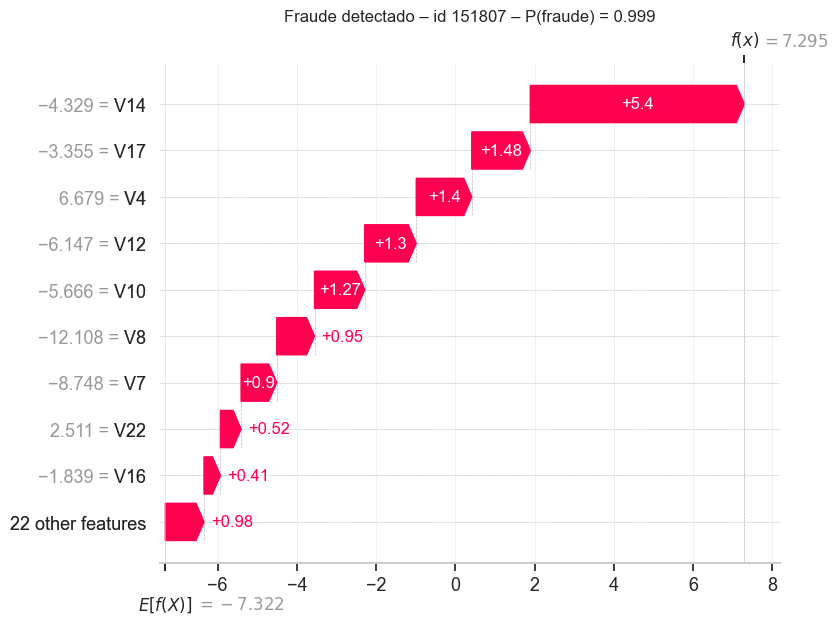

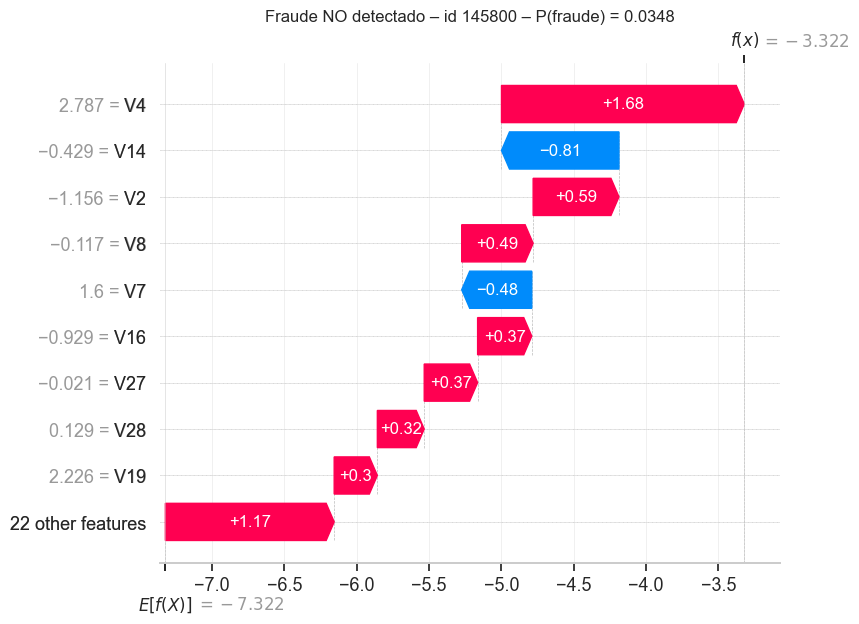

Fraudes de prueba no detectados por XGBoost: 17 | monto mediano: 1.79 € | monto total: 3,777.55 €


In [12]:
# Explicación local: el fraude de prueba con mayor probabilidad y un fraude que el modelo no detectó
prob = modelo_xgb.predict_proba(muestra[modelo_xgb.feature_names_in_])[:, 1]
es_fraude = muestra[TARGET].values == 1
umbral_xgb = umbrales["XGBoost"]["negocio"]
i_detectado = int(np.argmax(np.where(es_fraude, prob, -1)))
no_detectados = np.where(es_fraude & (prob < umbral_xgb))[0]

shap.plots.waterfall(valores_shap[i_detectado], max_display=10, show=False)
plt.title(f"Fraude detectado – id {muestra.index[i_detectado]} – P(fraude) = {prob[i_detectado]:.3f}")
guardar_figura("22_shap_fraude_detectado.png")
plt.show()

if len(no_detectados):
    i_fn = int(no_detectados[np.argmax(prob[no_detectados])])
    shap.plots.waterfall(valores_shap[i_fn], max_display=10, show=False)
    plt.title(f"Fraude NO detectado – id {muestra.index[i_fn]} – P(fraude) = {prob[i_fn]:.4f}")
    guardar_figura("23_shap_fraude_no_detectado.png")
    plt.show()
monto_fn = muestra.loc[es_fraude & (prob < umbral_xgb), "Amount"]
print(f"Fraudes de prueba no detectados por XGBoost: {len(no_detectados)} | "
      f"monto mediano: {monto_fn.median():.2f} € | monto total: {monto_fn.sum():,.2f} €")

---
## 5.8 Configuración para el despliegue
Se guarda `models/config_despliegue.json` con el modelo por defecto, los umbrales de todos los modelos y sus métricas en prueba. La app y la API lo leen al arrancar.

In [13]:
config = ev.guardar_config_despliegue(MEJOR_MODELO, {m: umbrales[m] for m in MODELOS}, tabla_test)
print("Guardado:", ev.RUTA_CONFIG_DESPLIEGUE.relative_to(RAIZ))
print({k: v for k, v in config.items() if k in ("mejor_modelo", "costo_revision", "precision_minima")})

Guardado: models\config_despliegue.json
{'mejor_modelo': 'XGBoost', 'costo_revision': 5.0, 'precision_minima': 0.7}


---
# Resumen de la Fase 5

### Política de umbral
Cada alerta cuesta 5 € de revisión y cada fraude no detectado cuesta su monto. El umbral de cada modelo se eligió en validación, minimizando el costo con la condición Precision ≥ 0,70. Para XGBoost el umbral resultó **0,059**, muy por debajo de 0,5: el modelo asigna probabilidades bajas incluso a muchos fraudes, y bajar el umbral recupera casos a un costo de revisión pequeño.

### Resultados en prueba (95 fraudes; umbral de negocio)

| Modelo | Precision | Recall | F1 | PR-AUC | ROC-AUC | Costo (€) | Ahorro |
|---|---|---|---|---|---|---|---|
| **XGBoost** | **0,830** | **0,821** | **0,825** | **0,829** | **0,972** | **4 248** | **71,2 %** |
| Stacking (RF + XGB) | 0,750 | 0,821 | 0,784 | 0,817 | 0,971 | 4 302 | 70,9 % |
| Random Forest | 0,745 | 0,800 | 0,772 | 0,813 | 0,967 | 4 297 | 70,9 % |
| DNN | 0,811 | 0,768 | 0,789 | 0,780 | 0,944 | 4 502 | 69,5 % |
| Regresión Logística | 0,787 | 0,779 | 0,783 | 0,695 | 0,956 | 4 278 | 71,0 % |
| Autoencoder | 0,735 | 0,263 | 0,388 | 0,493 | 0,946 | 13 393 | 9,3 % |

Sin modelo, el fraude de prueba cuesta 14 766 €.

### Modelo seleccionado: XGBoost
Elegido con el criterio fijado de antemano: empata con el Stacking en PR-AUC de validación (0,889) y es más simple. En prueba detecta **78 de 95 fraudes** con **16 falsas alarmas** entre 56 651 transacciones legítimas (0,028 %).

| Criterio de éxito (Fase 1) | Resultado en prueba | IC 95 % (bootstrap) | ¿Cumple? |
|---|---|---|---|
| Recall ≥ 0,80 | 0,821 | [0,742; 0,897] | ✔ |
| Precision ≥ 0,70 | 0,830 | [0,750; 0,899] | ✔ |
| PR-AUC ≥ 0,80 | 0,829 | [0,755; 0,901] | ✔ |
| Costo menor que sin modelo | 4 248 € frente a 14 766 € | — | ✔ |

Los intervalos son amplios porque la prueba tiene solo 95 fraudes: el límite inferior del Recall y del PR-AUC queda por debajo de 0,80, así que el cumplimiento debe confirmarse con más datos.

### Hallazgos de la evaluación
1. **El umbral importa más que el balanceo.** Con el umbral de 0,5, XGBoost tiene Recall 0,737 (no cumple el criterio); con el umbral de negocio sube a 0,821, a cambio de 22 alertas más. El umbral que maximiza el F1 favorece la precisión (0,972) pero deja escapar más fraudes (Recall 0,726).
2. **El umbral elegido en validación no es exactamente el óptimo en prueba.** En prueba, el umbral 0,5 da un costo algo menor (4 185 € frente a 4 248 €), una diferencia de 1,5 % debida a la variación entre muestras pequeñas. Se mantiene el umbral de validación para no ajustar con la prueba.
3. **Con y sin SMOTE (prueba).** XGBoost sin balanceo obtiene el mayor PR-AUC (0,833) frente a 0,820 con SMOTE y 0,819 con pesos. En Random Forest, SMOTE mejora el PR-AUC (0,817 frente a 0,790) pero baja la Precision a 0,70. En la DNN, los pesos de clase y SMOTE empeoran el PR-AUC (0,669 y 0,719 frente a 0,800). Se confirma lo observado en validación: SMOTE no es necesario cuando el umbral se optimiza.
4. **ROC-AUC engañoso.** Todos los supervisados superan 0,94 de ROC-AUC, incluso la Regresión Logística, cuyo PR-AUC (0,695) es claramente inferior. La curva PR separa los modelos mucho mejor.
5. **Autoencoder.** Con la restricción Precision ≥ 0,70 su umbral resulta muy alto y solo detecta 26 % de los fraudes. Sin etiquetas no alcanza a los supervisados, pero su ROC-AUC (0,946) muestra que ordena bien las transacciones; es útil como señal complementaria de anomalía.
6. **Sensibilidad al costo de revisión.** El umbral de XGBoost no cambia entre 1 € y 10 € por alerta (ahorro entre 68 % y 74 %). Solo con 20 € o más conviene el umbral más exigente (0,549), con Recall 0,726. La decisión es robusta frente al supuesto de costo.
7. **Fraudes no detectados.** Los 17 fraudes que XGBoost no detecta suman 3 778 € y tienen un monto mediano de 1,79 €. Son en su mayoría transacciones pequeñas (compatibles con *card testing*) cuyas variables se parecen a las legítimas.

### Interpretabilidad (SHAP sobre XGBoost)
Las variables con mayor impacto medio son **V14** (1,16), **V4** (1,11), V8 (0,46), V12 (0,43), V11 (0,33) y V10 (0,30). Coinciden con las más separables del análisis exploratorio (KS de la Fase 2: V14, V10, V12, V4, V11). Valores **bajos** de V14, V12 y V10 y valores **altos** de V4 y V11 empujan la predicción hacia fraude. `Amount_log` y la hora tienen un aporte pequeño: el monto, por sí solo, distingue poco. En el fraude no detectado analizado, un V4 alto empuja hacia fraude, pero V14 (−0,43, un valor normal) lo compensa: el fraude "no se parece" a los fraudes típicos en su variable más importante.